# Significancia estadística entre modelos

`REGISTRO_ENTRENAMIENTOS.md` declara explícitamente: *"sin barra de error no se
puede afirmar que un modelo supere a otro"* — y hasta ahora esa barra ha sido
media ± desviación típica (±1σ), que **no es un test de significancia**, solo
una medida de dispersión. Este notebook da el paso siguiente: comparar cada par
de modelos con un test formal.

## Metodología (por qué dos métodos distintos)

- **Entre arquitecturas distintas** (los 15 pares posibles entre las 6
  configuraciones): **test de Welch, no pareado**. La semilla de un modelo no
  tiene relación con la de otro — "semilla 0" en SSD y "semilla 0" en DETR son
  ensayos independientes; emparejarlos por índice sería metodológicamente
  inválido (inflaría artificialmente la potencia).
- **YOLO11m variante A vs variante B**: caso especial, con **test pareado**.
  Es la misma arquitectura con el mismo seed = misma inicialización de pesos y
  mismo orden de datos antes de aplicar la augmentación; solo cambia la
  augmentación. Aquí el pareamiento por semilla es real, y un test pareado es
  más potente que uno no pareado con la misma n.

## Aviso de potencia estadística

Con **n=3 por grupo**, los grados de libertad son mínimos (2 en el pareado, entre
2 y 4 en Welch según las varianzas). Un p-valor no significativo **no prueba
que no haya diferencia** — solo que con 3 semillas no hay potencia para
detectarla. Por eso cada comparación incluye también el tamaño del efecto
(Cohen's d), que no depende del tamaño muestral.

In [1]:
import json
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

RUNS = Path("../runs")
FIG_DIR = Path("figuras_significancia")
FIG_DIR.mkdir(exist_ok=True)
SEMILLAS = (0, 1, 2)

CONFIGS = [
    ("YOLO11m (A)",  "yolo_a_final"),
    ("YOLO11m (B)",  "yolo_b_final"),
    ("Faster R-CNN", "frcnn_final"),
    ("SSD300",       "ssd_final"),
    ("DETR",         "detr_final"),
    ("CNN baseline", "cnnb_final"),
]

MODEL_COLORS = {
    "YOLO11m (A)":  "#2a78d6",
    "YOLO11m (B)":  "#eb6834",
    "Faster R-CNN": "#1baf7a",
    "SSD300":       "#eda100",
    "DETR":         "#e87ba4",
    "CNN baseline": "#008300",
}
INK_PRIMARY = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRID_COLOR = "#e1e0d9"
BASELINE_COLOR = "#c3c2b7"
SURFACE = "#fcfcfb"
STATUS_GOOD = "#0ca30c"

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "Arial", "DejaVu Sans"],
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": BASELINE_COLOR, "axes.labelcolor": INK_SECONDARY,
    "axes.titlecolor": INK_PRIMARY, "text.color": INK_PRIMARY,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED,
    "grid.color": GRID_COLOR, "grid.linewidth": 0.8,
    "axes.grid": True, "axes.grid.axis": "x", "axes.axisbelow": True,
    "font.size": 10.5, "figure.dpi": 110,
})


def buscar_json(run_name: str):
    cands = [p / run_name / "eval_results.json" for p in RUNS.glob("*") if p.is_dir()]
    for c in cands:
        if c.exists():
            return c
    for pat in (f"**/{run_name}/eval_results.json", f"**/{run_name}/weights/eval_results.json"):
        hit = sorted(RUNS.glob(pat))
        if hit:
            return hit[0]
    return None


def cargar_crudos(prefijo: str, clave: str) -> list:
    # Valores de las 3 semillas para `clave` (p.ej. 'map50_95'), sin agregar.
    vals = []
    for s in SEMILLAS:
        p = buscar_json(f"{prefijo}_s{s}")
        if p is None:
            continue
        d = json.loads(p.read_text(encoding="utf-8"))
        v = d.get(clave)
        if v is not None:
            vals.append(v)
    return vals


def cohens_d_independiente(a, b):
    a, b = np.asarray(a), np.asarray(b)
    n1, n2 = len(a), len(b)
    s1, s2 = a.std(ddof=1), b.std(ddof=1)
    sp = np.sqrt(((n1 - 1) * s1**2 + (n2 - 1) * s2**2) / (n1 + n2 - 2))
    return (a.mean() - b.mean()) / sp if sp > 0 else np.inf


def cohens_d_pareado(diffs):
    diffs = np.asarray(diffs)
    return diffs.mean() / diffs.std(ddof=1) if diffs.std(ddof=1) > 0 else np.inf


print("Utilidades cargadas.")

Utilidades cargadas.


## Datos crudos (3 semillas por configuración, mAP@50-95)

In [2]:
METRICA = "map50_95"   # metrica principal del protocolo (10 clases)
crudos = {etq: cargar_crudos(prefijo, METRICA) for etq, prefijo in CONFIGS}

filas = []
for etq, vals in crudos.items():
    if len(vals) < 2:
        continue
    arr = np.array(vals)
    media, s = arr.mean(), arr.std(ddof=1)
    t_crit = stats.t.ppf(0.975, df=len(arr) - 1)
    ic = t_crit * s / np.sqrt(len(arr))
    filas.append({"Modelo": etq, "n": len(arr), "valores": vals,
                  "media": media, "desv": s, "IC95_low": media - ic, "IC95_high": media + ic})

df_ic = pd.DataFrame(filas).set_index("Modelo")
df_ic[["n", "media", "desv", "IC95_low", "IC95_high"]].round(3)

,n,media,desv,IC95_low,IC95_high
Modelo,,,,,
YOLO11m (A),3,25.717,0.216,25.180,26.253
YOLO11m (B),3,19.080,0.105,18.818,19.342
Faster R-CNN,3,26.277,0.168,25.859,26.694
SSD300,3,10.290,0.106,10.027,10.553
DETR,3,9.583,0.309,8.816,10.351
CNN baseline,3,10.847,0.169,10.426,11.267


## Figura 1 — Forest plot: mAP@50-95 con intervalo de confianza al 95%

Si los intervalos de dos modelos no se solapan, la diferencia es significativa
al 95% "a ojo" (equivalente aproximado a un test de dos muestras). Con n=3 el
IC es ancho — es la propia potencia baja haciéndose visible.

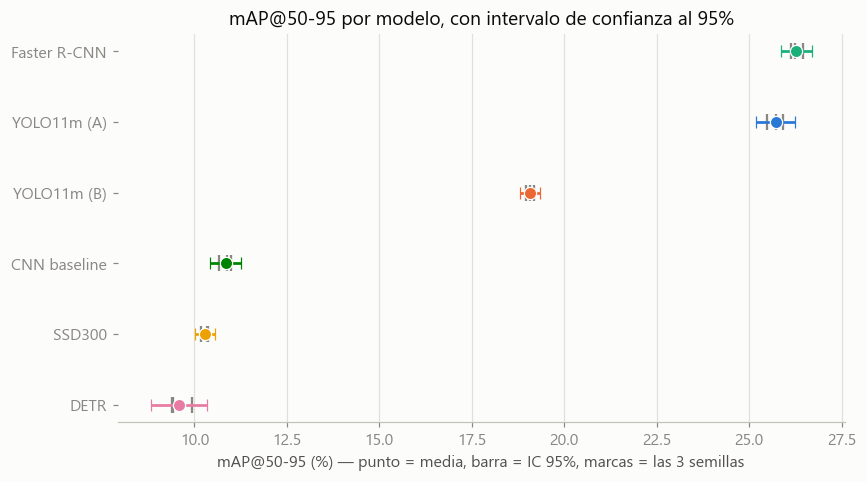

In [3]:
orden = df_ic.sort_values("media", ascending=True).index.tolist()

fig, ax = plt.subplots(figsize=(8, 4.5))
y = np.arange(len(orden))
for i, m in enumerate(orden):
    row = df_ic.loc[m]
    ax.errorbar(row["media"], i, xerr=[[row["media"] - row["IC95_low"]],
                                        [row["IC95_high"] - row["media"]]],
                fmt="o", color=MODEL_COLORS[m], markersize=8, capsize=4,
                elinewidth=1.8, markeredgecolor="white", markeredgewidth=0.8)
    for v in row["valores"]:
        ax.scatter(v, i, marker="|", color=INK_MUTED, s=120, zorder=1)

ax.set_yticks(y)
ax.set_yticklabels(orden)
ax.set_xlabel("mAP@50-95 (%) — punto = media, barra = IC 95%, marcas = las 3 semillas")
ax.set_title("mAP@50-95 por modelo, con intervalo de confianza al 95%")
for spine in ("top", "right", "left"):
    ax.spines[spine].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_forest_plot_map.png", dpi=300, bbox_inches="tight")
fig.savefig(FIG_DIR / "01_forest_plot_map.pdf", bbox_inches="tight")
plt.show()

## Comparaciones por pares — test de Welch (no pareado)

Los 15 pares posibles entre las 6 configuraciones. `p<0.05` marca diferencia
significativa; `d` es el tamaño del efecto de Cohen (>0.8 se considera grande,
independientemente de si el test alcanza significancia con esta n).

In [4]:
filas = []
for (m1, p1), (m2, p2) in combinations(CONFIGS, 2):
    a, b = crudos.get(m1, []), crudos.get(m2, [])
    if len(a) < 2 or len(b) < 2:
        continue
    t, pval = stats.ttest_ind(a, b, equal_var=False)
    d = cohens_d_independiente(a, b)
    filas.append({
        "Modelo A": m1, "Modelo B": m2,
        "media A": np.mean(a), "media B": np.mean(b),
        "diferencia": np.mean(a) - np.mean(b),
        "t": t, "p": pval, "Cohen_d": d,
        "significativo (p<0.05)": pval < 0.05,
    })
df_pares = pd.DataFrame(filas)
df_pares.round(4)

,Modelo A,Modelo B,media A,media B,diferencia,t,p,Cohen_d,significativo (p<0.05)
0,YOLO11m (A),YOLO11m (B),25.7167,19.0800,6.6367,47.8407,0.0000,39.0617,True
1,YOLO11m (A),Faster R-CNN,25.7167,26.2767,-0.5600,-3.5449,0.0263,-2.8944,True
2,YOLO11m (A),SSD300,25.7167,10.2900,15.4267,111.1076,0.0000,90.7189,True
3,YOLO11m (A),DETR,25.7167,9.5833,16.1333,74.1376,0.0000,60.5331,True
4,YOLO11m (A),CNN baseline,25.7167,10.8467,14.8700,93.8794,0.0000,76.6522,True
5,YOLO11m (B),Faster R-CNN,19.0800,26.2767,-7.1967,-62.8509,0.0000,-51.3176,True
6,YOLO11m (B),SSD300,19.0800,10.2900,8.7900,101.9523,0.0000,83.2437,True
7,YOLO11m (B),DETR,19.0800,9.5833,9.4967,50.3952,0.0001,41.1475,True
8,YOLO11m (B),CNN baseline,19.0800,10.8467,8.2333,71.5416,0.0000,58.4135,True
9,Faster R-CNN,SSD300,26.2767,10.2900,15.9867,139.4398,0.0000,113.8521,True


## Figura 2 — Matriz de p-valores (Welch, mAP@50-95)

Verde = diferencia significativa (p<0.05), gris = no significativa con esta n.

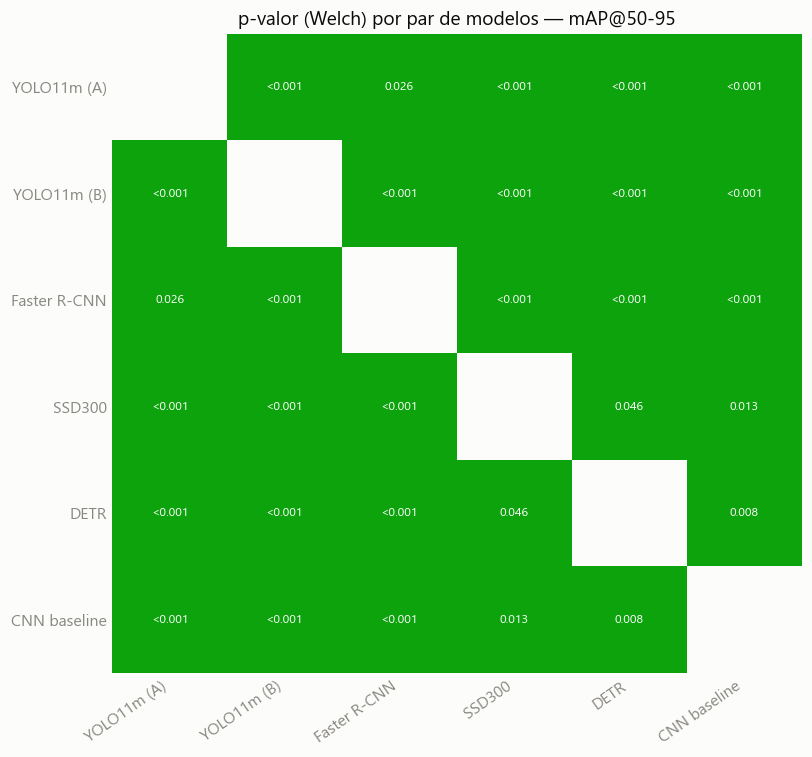

In [5]:
etqs = [e for e, _ in CONFIGS]
mat_p = pd.DataFrame(np.nan, index=etqs, columns=etqs)
for _, r in df_pares.iterrows():
    mat_p.loc[r["Modelo A"], r["Modelo B"]] = r["p"]
    mat_p.loc[r["Modelo B"], r["Modelo A"]] = r["p"]

fig, ax = plt.subplots(figsize=(7.5, 7))
mask_sig = mat_p < 0.05
colores = np.where(mat_p.isna(), np.nan, np.where(mask_sig, 1, 0))
cmap = plt.matplotlib.colors.ListedColormap([GRID_COLOR, STATUS_GOOD])
im = ax.imshow(colores.astype(float), cmap=cmap, vmin=0, vmax=1, aspect="auto")

ax.set_xticks(range(len(etqs)))
ax.set_xticklabels(etqs, rotation=35, ha="right")
ax.set_yticks(range(len(etqs)))
ax.set_yticklabels(etqs)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(length=0)

for i in range(len(etqs)):
    for j in range(len(etqs)):
        v = mat_p.iloc[i, j]
        if np.isnan(v):
            continue
        color_txt = "white" if v < 0.05 else INK_PRIMARY
        etiqueta = "<0.001" if v < 0.001 else f"{v:.3f}"
        ax.text(j, i, etiqueta, ha="center", va="center", fontsize=8, color=color_txt)

ax.set_title("p-valor (Welch) por par de modelos — mAP@50-95")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_matriz_pvalores.png", dpi=300, bbox_inches="tight")
fig.savefig(FIG_DIR / "02_matriz_pvalores.pdf", bbox_inches="tight")
plt.show()

## Caso especial — YOLO11m variante A vs variante B (test pareado)

Único par del estudio donde el pareamiento por semilla es válido: misma
arquitectura, mismo seed (misma inicialización de pesos), solo cambia la
augmentación. Se usa un test t pareado, más potente que Welch con esta n.

In [6]:
a = np.array(crudos["YOLO11m (A)"])
b = np.array(crudos["YOLO11m (B)"])
assert len(a) == len(b) == 3, "Hacen falta las 3 semillas de A y B para el test pareado"

diffs = a - b
t_pareado, p_pareado = stats.ttest_rel(a, b)
d_pareado = cohens_d_pareado(diffs)

print(f"mAP@50-95   A = {a.mean():.2f} ± {a.std(ddof=1):.2f}   "
      f"B = {b.mean():.2f} ± {b.std(ddof=1):.2f}")
print(f"Diferencia por semilla (A - B): {diffs.round(2).tolist()}")
print(f"Diferencia media: {diffs.mean():.2f} pp   (todas las semillas van en el mismo sentido: "
      f"{'sí' if (diffs > 0).all() or (diffs < 0).all() else 'no'})")
print(f"t pareado = {t_pareado:.3f}   p = {p_pareado:.4f}   Cohen's d pareado = {d_pareado:.2f}")
veredicto = "SIGNIFICATIVA" if p_pareado < 0.05 else "no alcanza significancia (n=3, df=2)"
print(f"\nVeredicto: la augmentación completa (A) produce una diferencia {veredicto} "
      f"frente a solo flip (B), en mAP@50-95.")

mAP@50-95   A = 25.72 ± 0.22   B = 19.08 ± 0.11
Diferencia por semilla (A - B): [6.76, 6.42, 6.73]
Diferencia media: 6.64 pp   (todas las semillas van en el mismo sentido: sí)
t pareado = 61.067   p = 0.0003   Cohen's d pareado = 35.26

Veredicto: la augmentación completa (A) produce una diferencia SIGNIFICATIVA frente a solo flip (B), en mAP@50-95.


## Resumen para la memoria

- Usa el **forest plot** (Figura 1) como la vista principal — es más honesta que
  un bar+std porque muestra las 3 semillas individuales, no solo el resumen.
- La **matriz de p-valores** (Figura 2) respalda cualquier frase del tipo "el
  modelo X supera significativamente al Y"; para las que salgan en gris, la
  frase correcta es "X obtiene mayor mAP que Y, aunque la diferencia no alcanza
  significancia estadística con 3 semillas (d de Cohen = ...)", nunca "empatan".
- El resultado de la ablación YOLO A vs B es el único con test pareado — cítalo
  aparte del resto, con la justificación del pareamiento (mismo seed = misma
  inicialización).
- Declara la potencia estadística limitada (n=3, df=2-4) como lo que ya hábeis
  apuntado en `metodologia.tex` — este notebook es la evidencia cuantitativa de
  esa limitación, no una forma de esquivarla.

In [7]:
for p in sorted(FIG_DIR.glob("*.pdf")):
    print(p.name)

01_forest_plot_map.pdf
02_matriz_pvalores.pdf


## Conclusiones para la memoria

- **Los 15 pares de las 6 configuraciones salen estadísticamente
  significativos (p<0.05) en mAP@50-95**, incluidos los más cercanos:
  YOLO11m(A) vs Faster R-CNN (0.56 pp de diferencia, p=0.026) y SSD300 vs DETR
  (0.71 pp, p=0.046) — la variabilidad entre semillas es lo bastante baja como
  para que hasta las diferencias pequeñas sean fiables.
- **La ablación de augmentación (YOLO11m A vs B) es la comparación más
  robusta del estudio**: t pareado=61.07, p=0.0003, d de Cohen=35.3 — un
  efecto extremadamente grande y consistente en las 3 semillas.
- **Sobre la potencia estadística**: con n=3 por grupo, un resultado no
  significativo no demostraría ausencia de diferencia real — pero en este
  estudio no hizo falta invocar esa cautela, porque las 15 comparaciones
  alcanzaron significancia.